# Gaussian naive Bayes: bank customer churn

Part of the ML Portfolio Model Zoo. Educational purposes only.

Given a customer's age, balance, product count, tenure and recent activity, estimate the probability that they leave the bank. The data is **synthetic**, generated from a known churn process.

In [1]:
import tempfile
from pathlib import Path

import pandas as pd
from IPython.display import Image, display
from train import *

# Everything here reuses train.py, so the notebook and the site always use the same pipeline.

## Data

In [2]:
data = make_data()
print(data.shape)
data.head()

(6000, 6)


,age,balance_k,products,tenure_years,active_member,target
0,46.0,55.0,2,10.0,yes,0
1,28.0,85.0,2,4.0,yes,0
2,52.0,19.0,1,1.0,yes,1
3,54.0,40.0,2,1.0,yes,0
4,18.0,9.0,2,8.0,yes,0


In [3]:
data.describe(include='all').T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
age,6000.0,NaN,NaN,NaN,42.072333,12.645464,18.0,33.0,42.0,50.0,87.0
balance_k,6000.0,NaN,NaN,NaN,56.132333,39.756328,0.0,27.0,47.0,75.0,250.0
products,6000.0,NaN,NaN,NaN,1.783167,0.801825,1.0,1.0,2.0,2.0,4.0
tenure_years,6000.0,NaN,NaN,NaN,6.592,4.533023,0.0,3.0,6.0,9.0,30.0
active_member,6000,2,yes,3501,NaN,NaN,NaN,NaN,NaN,NaN,NaN
target,6000.0,NaN,NaN,NaN,0.345833,0.475679,0.0,0.0,0.0,1.0,1.0


## Train and evaluate

`train_and_evaluate()` fits the scikit-learn pipeline, scores it on a held-out split, exports it to ONNX and asserts that onnxruntime reproduces scikit-learn's predictions.

In [4]:
result = train_and_evaluate()
print(f"accuracy {result.metrics['accuracy']:.3f}   ROC AUC {result.metrics['roc_auc']:.3f}")
print(f"majority-class baseline {result.metrics['majority_baseline']:.3f}")
print(f"ONNX vs sklearn max abs diff: {result.metrics['onnx_max_abs_diff']:.1e}")

accuracy 0.719   ROC AUC 0.790
majority-class baseline 0.654
ONNX vs sklearn max abs diff: 1.0e-06


## Charts

The same charts the site shows, written to a temporary folder.

Naive Bayes models each feature's distribution per class; these are the shapes it compares.


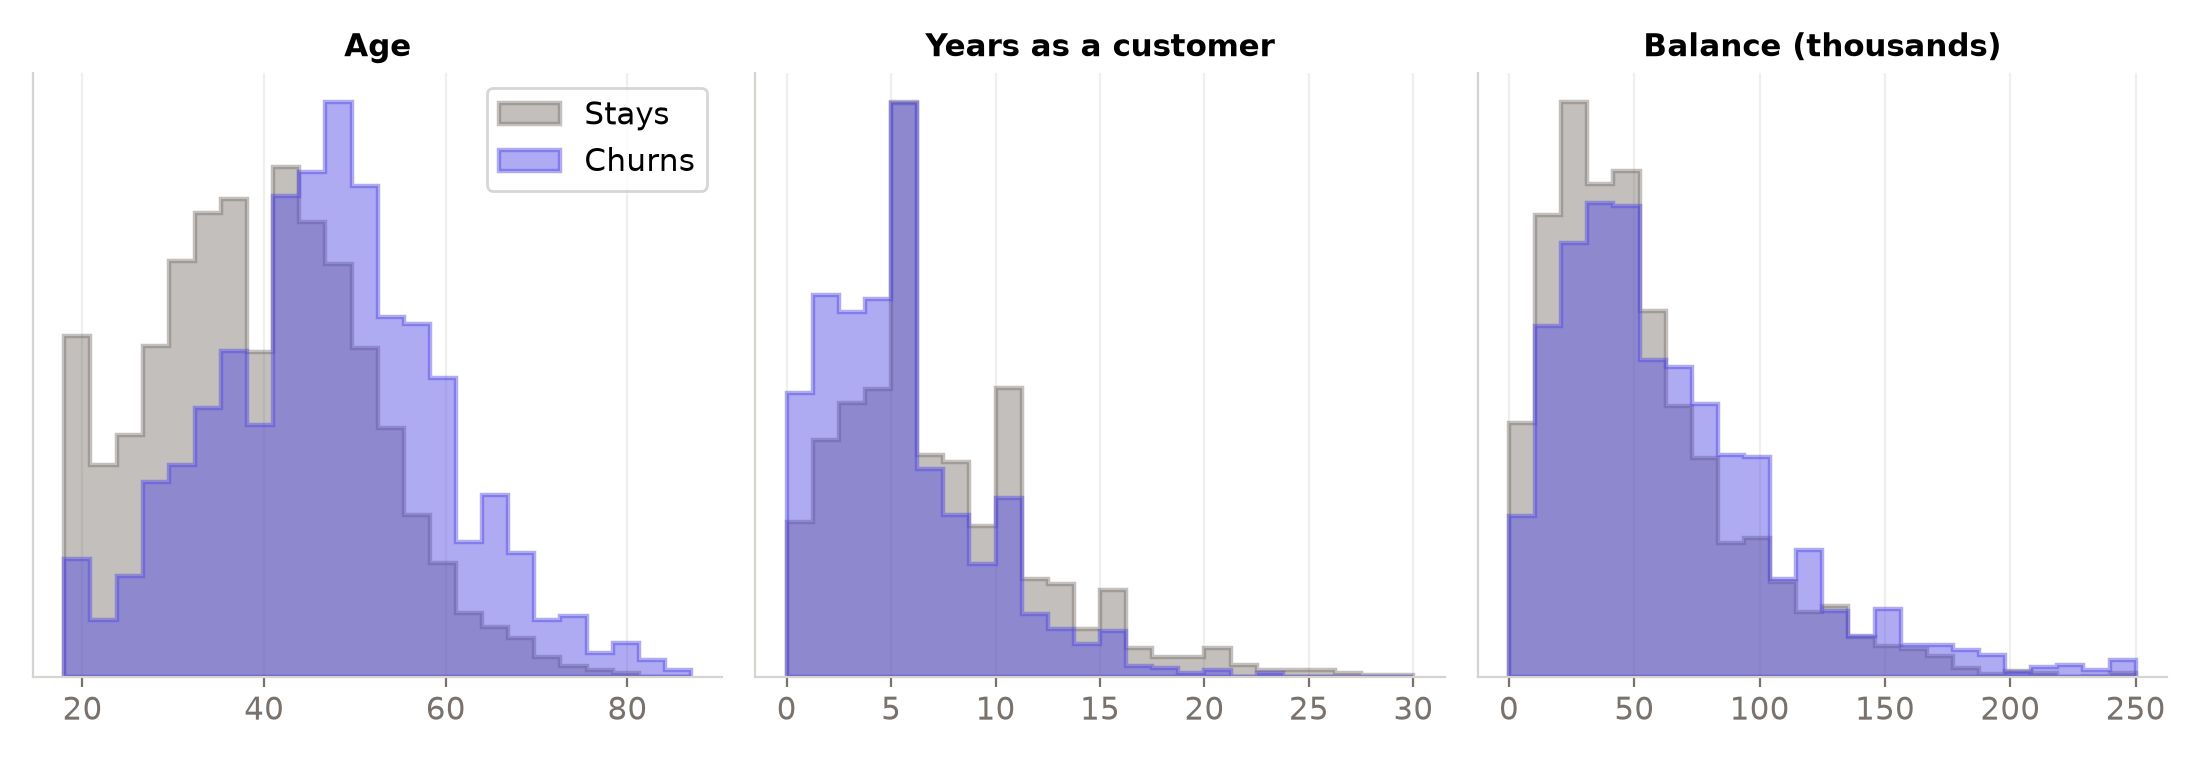

ROC curve on held-out customers.


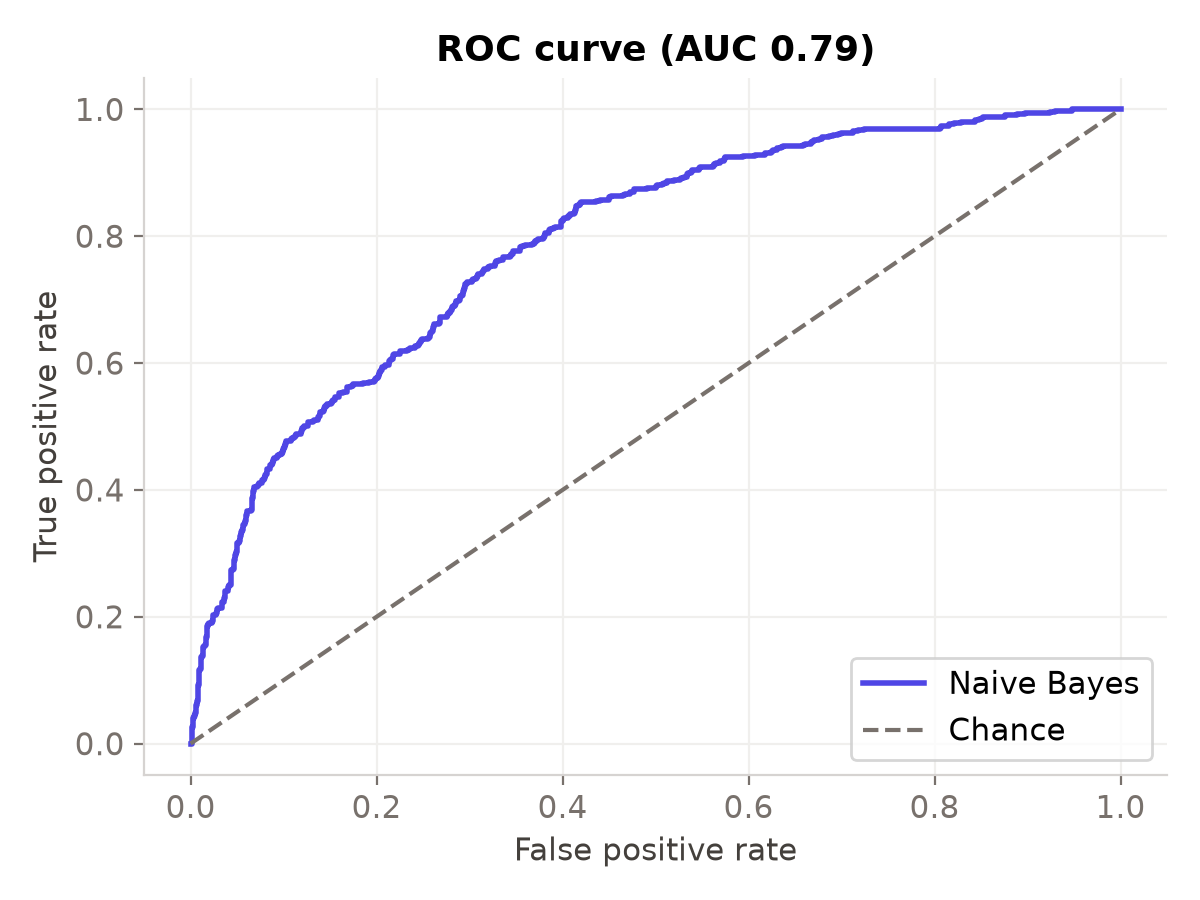

Naive Bayes is often over-confident: probabilities drift from observed rates.


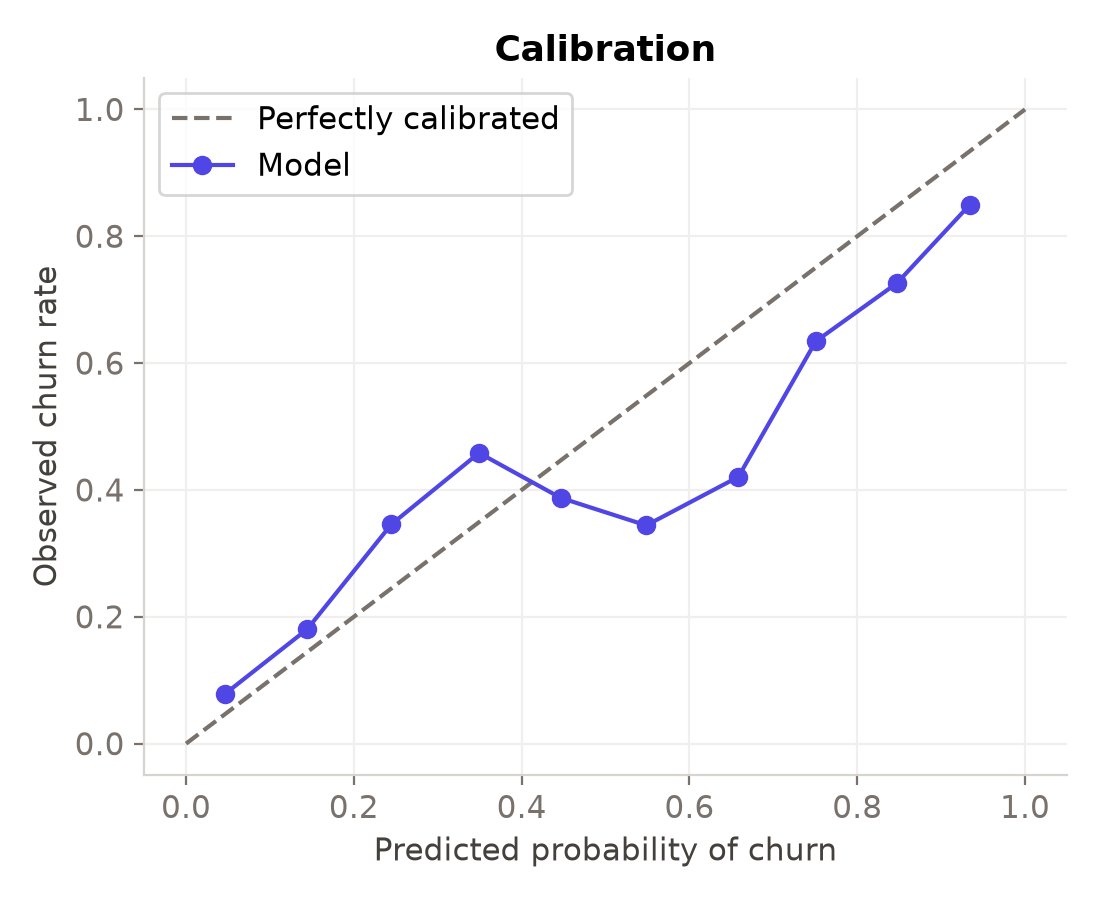

Confusion matrix on held-out data.


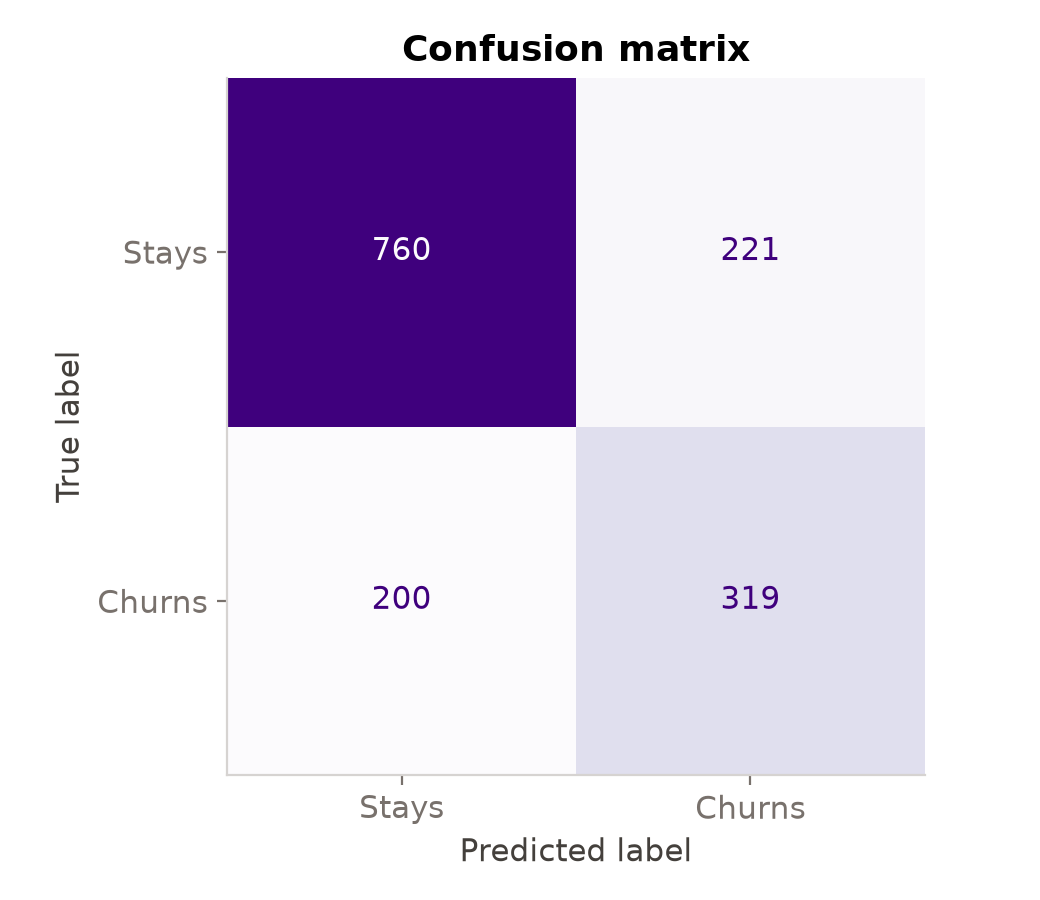

In [5]:
out = Path(tempfile.mkdtemp())
charts = make_charts(result, out)
for c in charts:
    print(c['caption'])
    display(Image(filename=str(out / c['file']), width=620))

## Predict with the exported ONNX model

In [6]:
example = pd.DataFrame([PRESETS[1]["values"]])[ALL_COLUMNS]
_, probs = onnx_predict(result.model_bytes, example)
print("At-risk preset ->", LABELS[int(probs[0].argmax())], f"(P(churn) = {probs[0][1]:.1%})")

At-risk preset -> Churns (P(churn) = 97.4%)


## Site artefacts

Run `uv run python train.py` to write `model.onnx`, `schema.json`, the charts and the .NET parity fixtures into the web app. See the README for details.